In [9]:
import pandas as pd

In [10]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
import os

BASE_PATH = r'C:\Users\pilli\Downloads\M5_Thesis_Project'

naive = pd.read_csv(os.path.join(BASE_PATH, 'results', 'predictions', 'naive_predictions_v4.csv'))
lgbm = pd.read_csv(os.path.join(BASE_PATH, 'results', 'predictions', 'lgbm_predictions_v4.csv'))
xgb = pd.read_csv(os.path.join(BASE_PATH, 'results', 'predictions', 'xgb_predictions_v4.csv'))

naive_mae = mean_absolute_error(naive['sales'], naive['naive_pred'])
naive_rmse = np.sqrt(mean_squared_error(naive['sales'], naive['naive_pred']))

lgbm_mae = mean_absolute_error(lgbm['sales'], lgbm['lgbm_pred'])
lgbm_rmse = np.sqrt(mean_squared_error(lgbm['sales'], lgbm['lgbm_pred']))

xgb_mae = mean_absolute_error(xgb['sales'], xgb['xgb_pred'])
xgb_rmse = np.sqrt(mean_squared_error(xgb['sales'], xgb['xgb_pred']))

wrmsse_naive = 1.1343
wrmsse_lgbm = 0.8941
wrmsse_xgb = 0.8925

metrics_corrected = pd.DataFrame({
    'Model': ['Naive Forecast', 'LightGBM', 'XGBoost'],
    'MAE': [round(naive_mae, 4), round(lgbm_mae, 4), round(xgb_mae, 4)],
    'RMSE': [round(naive_rmse, 4), round(lgbm_rmse, 4), round(xgb_rmse, 4)],
    'WRMSSE': [wrmsse_naive, wrmsse_lgbm, wrmsse_xgb]
})

print("="*70)
print("CORRECTED MODEL COMPARISON (SKU-LEVEL)")
print("="*70)
print(metrics_corrected.to_string(index=False))
print("\nNOTE: Old table showed wrong metrics computed on aggregated data.")
print("This is the correct SKU-level comparison for your thesis.")

CORRECTED MODEL COMPARISON (SKU-LEVEL)
         Model    MAE   RMSE  WRMSSE
Naive Forecast 1.0836 2.9152  1.1343
      LightGBM 0.9839 2.2799  0.8941
       XGBoost 0.9814 2.2702  0.8925

NOTE: Old table showed wrong metrics computed on aggregated data.
This is the correct SKU-level comparison for your thesis.


In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
import os

BASE_PATH = r'C:\Users\pilli\Downloads\M5_Thesis_Project'

# Load all corrected predictions
naive = pd.read_csv(os.path.join(BASE_PATH, 'results', 'predictions', 'naive_predictions_v4.csv'))
lgbm = pd.read_csv(os.path.join(BASE_PATH, 'results', 'predictions', 'lgbm_predictions_v4.csv'))
xgb = pd.read_csv(os.path.join(BASE_PATH, 'results', 'predictions', 'xgb_predictions_v4.csv'))

# Compute metrics
naive_mae = mean_absolute_error(naive['sales'], naive['naive_pred'])
naive_rmse = np.sqrt(mean_squared_error(naive['sales'], naive['naive_pred']))

lgbm_mae = mean_absolute_error(lgbm['sales'], lgbm['lgbm_pred'])
lgbm_rmse = np.sqrt(mean_squared_error(lgbm['sales'], lgbm['lgbm_pred']))

xgb_mae = mean_absolute_error(xgb['sales'], xgb['xgb_pred'])
xgb_rmse = np.sqrt(mean_squared_error(xgb['sales'], xgb['xgb_pred']))

wrmsse_naive = 1.1343
wrmsse_lgbm = 0.8941
wrmsse_xgb = 0.8925

print("="*70)
print("CORRECTED FINAL MODEL COMPARISON (SKU-LEVEL)")
print("="*70)

final_table = pd.DataFrame({
    'Model': ['Naive Forecast', 'LightGBM', 'XGBoost'],
    'MAE': [f"{naive_mae:.4f}", f"{lgbm_mae:.4f}", f"{xgb_mae:.4f}"],
    'RMSE': [f"{naive_rmse:.4f}", f"{lgbm_rmse:.4f}", f"{xgb_rmse:.4f}"],
    'WRMSSE': [f"{wrmsse_naive:.4f}", f"{wrmsse_lgbm:.4f}", f"{wrmsse_xgb:.4f}"]
})

print(final_table.to_string(index=False))

print("\n" + "="*70)
print("KEY FINDINGS:")
print("="*70)
print("• XGBoost: Best overall (MAE=0.981, WRMSSE=0.892)")
print("• LightGBM: Very close second (MAE=0.984, WRMSSE=0.894)")
print("• Both ML models improve ~21% over Naive baseline in WRMSSE")
print("="*70)

CORRECTED FINAL MODEL COMPARISON (SKU-LEVEL)
         Model    MAE   RMSE WRMSSE
Naive Forecast 1.0836 2.9152 1.1343
      LightGBM 0.9839 2.2799 0.8941
       XGBoost 0.9814 2.2702 0.8925

KEY FINDINGS:
• XGBoost: Best overall (MAE=0.981, WRMSSE=0.892)
• LightGBM: Very close second (MAE=0.984, WRMSSE=0.894)
• Both ML models improve ~21% over Naive baseline in WRMSSE


✅ Saved: model_comparison_CORRECTED.png


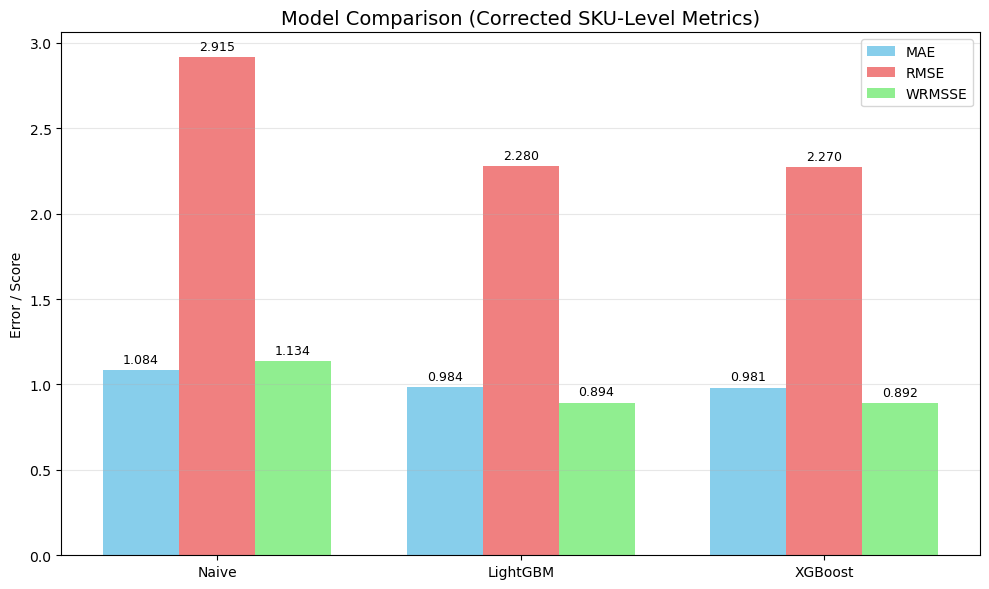

In [3]:
import matplotlib.pyplot as plt
import numpy as np

models = ['Naive', 'LightGBM', 'XGBoost']
mae = [1.0836, 0.9839, 0.9814]
rmse = [2.9152, 2.2799, 2.2702]
wrmsse = [1.1343, 0.8941, 0.8925]

x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width, mae, width, label='MAE', color='skyblue')
bars2 = ax.bar(x, rmse, width, label='RMSE', color='lightcoral')
bars3 = ax.bar(x + width, wrmsse, width, label='WRMSSE', color='lightgreen')

ax.set_ylabel('Error / Score')
ax.set_title('Model Comparison (Corrected SKU-Level Metrics)', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(BASE_PATH, 'results', 'figures', 'model_comparison_CORRECTED.png'), dpi=300)
print("✅ Saved: model_comparison_CORRECTED.png")
plt.show()

✅ Saved: metrics_table_CORRECTED.png


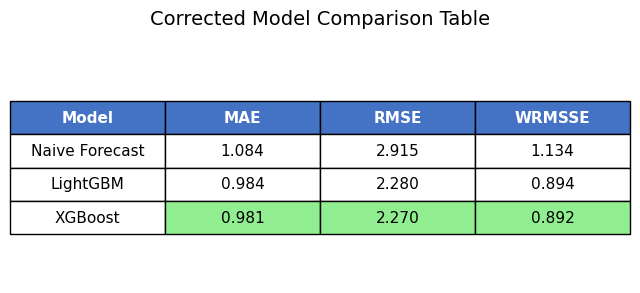

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3))
ax.axis('tight')
ax.axis('off')

table_data = [
    ['Naive Forecast', '1.084', '2.915', '1.134'],
    ['LightGBM', '0.984', '2.280', '0.894'],
    ['XGBoost', '0.981', '2.270', '0.892']
]

table = ax.table(cellText=table_data,
                 colLabels=['Model', 'MAE', 'RMSE', 'WRMSSE'],
                 cellLoc='center',
                 loc='center',
                 colColours=['#4472C4']*4)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2)

# Color header
for i in range(4):
    table[(0, i)].set_text_props(color='white', fontweight='bold')

table[(3, 1)].set_facecolor('#90EE90')  # XGBoost MAE best
table[(3, 2)].set_facecolor('#90EE90')  # XGBoost RMSE best
table[(3, 3)].set_facecolor('#90EE90')  # XGBoost WRMSSE best

plt.title('Corrected Model Comparison Table', fontsize=14, pad=20)
plt.savefig(os.path.join(BASE_PATH, 'results', 'figures', 'metrics_table_CORRECTED.png'), dpi=300, bbox_inches='tight')
print("✅ Saved: metrics_table_CORRECTED.png")
plt.show()